# 구조화 출력과 검증

**이 노트북에서 할 일**

1. 같은 요청을 일반 호출과 구조화 호출로 보내, 문장 답과 칸이 정해진 카드를 비교합니다.
2. 카드 양식에 칸과 범위 규칙을 적고, 원본 답과 읽은 카드를 함께 받습니다.
3. 범위 규칙을 설명에만 적은 양식과 규칙으로 적은 양식에 같은 질문을 보내 결과를 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.
인터넷 서비스의 모델 `gpt-5.4-mini`에 요청을 모두 6번 보냅니다. 실행 시간은 1분 안팎입니다.
예상 비용은 0.01달러 미만입니다(06절 4절에서 2026-09-17에 확인한 공식 요금 기준).

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
pydantic 2.13.5, python-dotenv 1.2.3도 함께 씁니다. 함께 설치되는 openai 패키지는 3.10.0입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch06-langchain-start`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

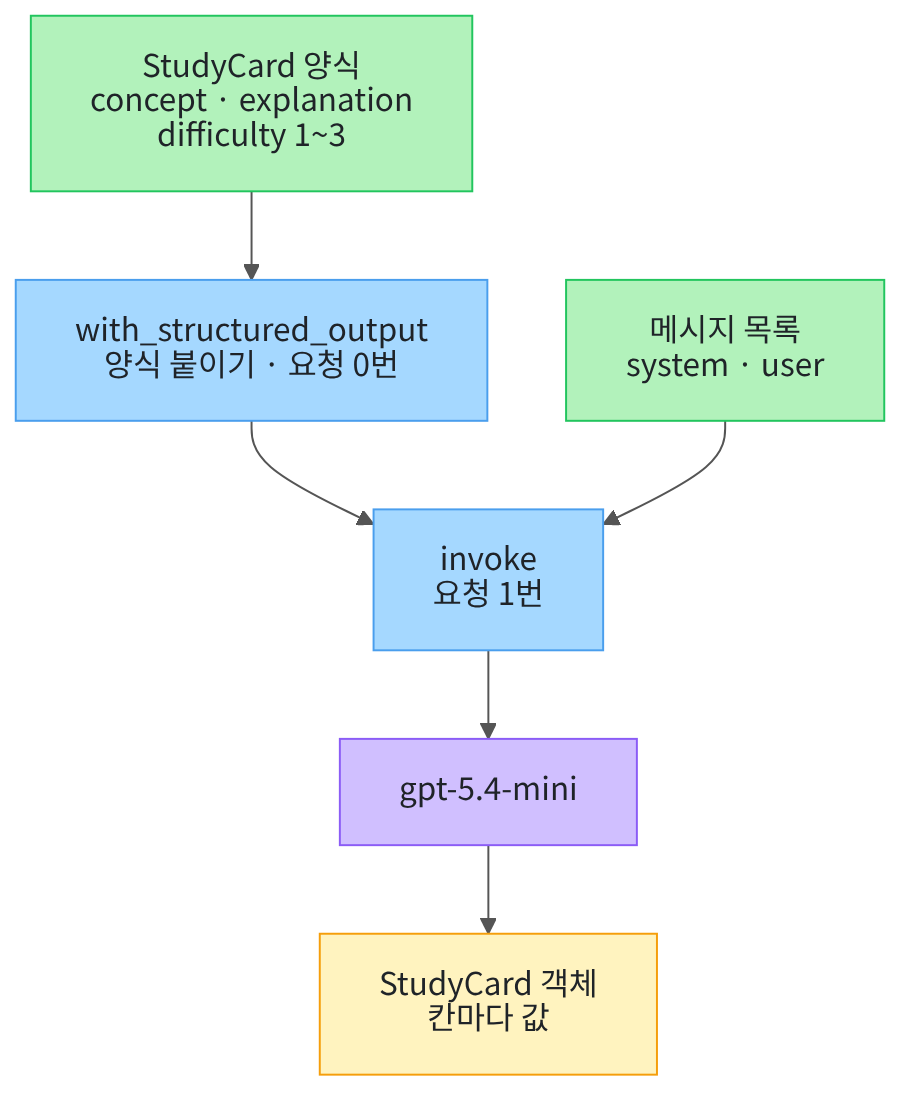

위에서 아래로 읽습니다. 초록 상자 두 개는 우리가 정한 카드 양식과 보낼 메시지 목록입니다.
파란 상자 두 개는 양식을 붙이는 줄과 요청을 보내는 줄입니다. 양식을 붙이는 줄은 요청을 보내지 않습니다.

맨 아래 노란 상자는 이 노트북 6절에서 받은 카드 객체입니다. 문장이 아니라 칸마다 값이 들어 있습니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
패키지 openai는 langchain-openai가 OpenAI 서버에 요청을 보낼 때 쓰는 패키지입니다. 10절 설명에서 이 판을 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "pydantic==2.13.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("pydantic:", version("pydantic"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0


pydantic: 2.13.5


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.10.0`, `pydantic: 2.13.5` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

01절과 같이 모델 객체를 만드는 함수를 불러옵니다.

In [2]:
# 모델 객체를 만드는 함수를 불러옵니다
from langchain.chat_models import init_chat_model

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 문장으로 받은 답 다시 보기

이번 절의 질문은 LangChain 메시지 객체 하나를 학습 카드로 만들어 달라는 요청입니다.
카드에는 개념 이름, 한 문장 설명, 1~3 난이도를 적게 합니다. 01절처럼 `(역할, 내용)` 튜플 목록으로 적습니다.

실행 전에 예상합니다. 01·02절처럼 역할 이름 system과 user가 한 줄씩 나올 것입니다.

In [5]:
# 학습 카드를 만들어 달라는 공통 지시와 이번 질문을 튜플 목록에 담습니다
messages = [
    ("system", "초급 학습자를 위한 학습 카드를 만듭니다."),
    ("user", "LangChain의 AIMessage를 학습 카드로 만드세요. 개념 이름, 한 문장 설명, 1~3 난이도를 적으세요."),
]
print("메시지 목록:")
for role, content in messages:
    print(role, "|", content)

메시지 목록:
system | 초급 학습자를 위한 학습 카드를 만듭니다.
user | LangChain의 AIMessage를 학습 카드로 만드세요. 개념 이름, 한 문장 설명, 1~3 난이도를 적으세요.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `system | 초급 학습자를 위한 학습 카드를 만듭니다.`, 둘째 줄은 user 질문입니다.
아직 목록만 만들었고 요청은 보내지 않았습니다.

이 목록을 01절과 같은 일반 호출로 보냅니다. 응답 객체의 종류를 보고, 답 글 속에 낱말 「난이도」가 있는지 봅니다.
연산자 `in`은 왼쪽 글이 오른쪽 글 안에 있으면 `True`를 줍니다. 답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.

실행 전에 예상합니다. 응답 객체는 AIMessage이고, 난이도 숫자는 답 글 속 어딘가에 섞여 있을 것입니다.

In [6]:
# 01절처럼 일반 호출로 보내고, 답이 어떤 자료형인지 봅니다(요청 1번)
response = model.invoke(messages)
print("응답 객체 종류:", type(response).__name__)
print("답 글 속에 난이도가 있는가:", "난이도" in response.text)
print("답:")
print(response.text)

응답 객체 종류: AIMessage
답 글 속에 난이도가 있는가: True
답:
### 학습 카드: AIMessage

- **개념 이름:** AIMessage  
- **한 문장 설명:** LangChain에서 AI가 생성한 응답 메시지를 나타내는 객체입니다.  
- **난이도:** 1


**결과 읽기** — 첫 두 줄은 `응답 객체 종류: AIMessage`와 `답 글 속에 난이도가 있는가: True`입니다.
라벨 줄 아래 답은 글 한 덩어리이고, 개념 이름·설명·난이도가 줄마다 섞여 있습니다.

프로그램이 난이도 숫자만 쓰려면 글 속에서 그 자리를 찾아야 합니다. 답의 줄 모양은 실행마다 달라질 수 있습니다.
그래서 이번 절은 받을 칸을 먼저 정해 두고 답을 받습니다.

## 3. 카드 양식 정하기

클래스 `BaseModel`은 Pydantic 라이브러리가 주는 양식 틀입니다. 이 틀로 만든 클래스는 칸마다 적은 자료형과 규칙으로 값을 검사합니다.
클래스 이름 뒤 괄호에 `BaseModel`을 적으면, 그 틀의 값 검사 기능을 물려받은 양식이 됩니다.
칸 이름이 인쇄된 신청서 양식과 비슷합니다. 아래 `StudyCard`는 칸 세 개를 가진 카드 양식입니다.

양식의 칸을 필드(field)라고 부릅니다. 칸 이름 뒤 `: str`, `: int`는 자료형입니다(Ch 2 07절 타입힌트).
함수 `Field()`는 칸에 설명과 규칙을 붙입니다. 규칙 `ge=1`은 1 이상, `le=3`은 3 이하입니다.
라이브러리 Pydantic은 Ch 2 10절에서 자세히 다룹니다. 기본 경로(A 트랙)에서 건너뛰었다면, 칸과 규칙을 적은 양식으로 읽으면 됩니다.

이 셀은 양식만 정의하므로 출력이 없습니다.

In [7]:
# 개념 이름·설명·난이도 세 칸을 가진 학습 카드 양식을 정합니다
from pydantic import BaseModel, Field

class StudyCard(BaseModel):
    concept: str = Field(description="개념 이름")
    explanation: str = Field(description="한 문장 설명")
    difficulty: int = Field(ge=1, le=3, description="1부터 3까지의 난이도")

출력은 없고, 이제 양식 `StudyCard`를 쓸 수 있습니다.

## 4. 양식 규칙을 먼저 손으로 확인하기

모델에 보내기 전에, 양식이 규칙대로 값을 검사하는지 직접 확인합니다. 이 절의 두 셀은 요청을 보내지 않습니다.
클래스 이름 뒤 괄호에 칸 이름을 키워드 인자로 넣으면 카드 객체가 만들어집니다. 키워드 인자는 Ch 2 05절, 객체 만들기는 06절에서 배웠습니다.

실행 전에 예상합니다. 난이도 2는 1~3 안이므로 카드가 만들어질 것입니다.

In [8]:
# 키워드 인자로 카드 하나를 직접 만들고 칸 값을 읽습니다(요청 없음)
sample_card = StudyCard(
    concept="AIMessage",
    explanation="모델이 쓴 답을 담는 메시지 객체입니다.",
    difficulty=2,
)
print("카드:", sample_card)
print("난이도 칸:", sample_card.difficulty)

카드: concept='AIMessage' explanation='모델이 쓴 답을 담는 메시지 객체입니다.' difficulty=2
난이도 칸: 2


**결과 읽기** — 첫 줄은 `카드: concept='AIMessage'`로 시작하고, 둘째 줄은 `난이도 칸: 2`입니다.
칸 값은 `sample_card.difficulty`처럼 점 뒤에 칸 이름을 적어 꺼냅니다.

이번에는 난이도 칸에 규칙 밖의 값 7을 넣습니다. 01절에서 본 값 검사 오류 `ValidationError`만 받습니다.

실행 전에 예상합니다. 3 이하라는 규칙에 걸려 카드가 만들어지지 않을 것입니다.

In [9]:
# 난이도 칸에 규칙 밖의 값 7을 넣고, 값 검사 오류만 받습니다(요청 없음)
from pydantic import ValidationError

try:
    wrong_card = StudyCard(
        concept="AIMessage",
        explanation="모델이 쓴 답을 담는 메시지 객체입니다.",
        difficulty=7,
    )
    print("카드:", wrong_card)
except ValidationError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:")
    print(error)

오류 종류: ValidationError
오류 메시지:
1 validation error for StudyCard
difficulty
  Input should be less than or equal to 3 [type=less_than_equal, input_value=7, input_type=int]
    For further information visit https://errors.pydantic.dev/2.13/v/less_than_equal


**결과 읽기** — 첫 줄은 `오류 종류: ValidationError`입니다. 라벨 줄 아래 오류 메시지는 `1 validation error for StudyCard`로 시작합니다.
그 아래 `difficulty` 줄이 걸린 칸 이름이고, `less than or equal to 3`이 걸린 규칙입니다.

넣은 값 7도 `input_value=7`로 적혀 있습니다. 오류 메시지만 보고 어느 칸의 어떤 규칙인지 알 수 있습니다.

## 5. 모델 객체에 양식 붙이기

메서드 `with_structured_output()`은 모델 객체에 카드 양식을 붙인 호출 객체를 만듭니다.
괄호 안에는 카드 객체가 아니라 클래스 이름 `StudyCard`를 괄호 없이 넣습니다. 만들 카드의 양식을 알려 주는 것입니다.

01절의 `init_chat_model()`처럼 이 줄도 준비만 합니다. 실행 전에 예상합니다. 요청은 0번이고 호출 객체 종류만 출력될 것입니다.

In [10]:
# 모델 객체에 카드 양식을 붙여 구조화 호출 객체를 만듭니다(이 셀은 요청을 보내지 않습니다)
structured_model = model.with_structured_output(StudyCard)
print("호출 객체 종류:", type(structured_model).__name__)

호출 객체 종류: RunnableSequence


**결과 읽기** — 출력 줄은 `호출 객체 종류: RunnableSequence`입니다. 여러 단계를 차례로 잇는 LangChain 객체라는 뜻입니다.
설치한 langchain-openai 1.6.0 소스로 두 단계를 확인했습니다. 모델 호출 단계 뒤에 답을 카드로 읽는 단계가 이어져 있습니다.

## 6. 구조화 호출로 카드 받기

2절과 같은 메시지 목록을 이번에는 구조화 호출 객체로 보냅니다. 부르는 메서드는 똑같이 `invoke()`입니다.
받은 결과의 종류와 칸 값을 하나씩 출력합니다. 마지막 줄의 `assert`는 결과 종류가 StudyCard인지 확인합니다.

실행 전에 예상합니다. 결과는 AIMessage가 아니라 카드 객체이고, 난이도 칸은 정수일 것입니다.

In [11]:
# 2절과 같은 메시지 목록을 보내고, 카드 객체로 받습니다(요청 1번)
card = structured_model.invoke(messages)
card_type = type(card).__name__
print("결과 종류:", card_type)
print("개념 이름:", card.concept)
print("설명:", card.explanation)
print("난이도:", card.difficulty)
print("난이도의 자료형:", type(card.difficulty).__name__)
assert card_type == "StudyCard"

결과 종류: StudyCard
개념 이름: AIMessage
설명: LangChain에서 AI가 생성한 응답 내용을 담는 메시지 객체입니다.
난이도: 1
난이도의 자료형: int


**결과 읽기** — 첫 줄은 `결과 종류: StudyCard`이고, 마지막 두 줄은 `난이도: 1`과 `난이도의 자료형: int`입니다.
`assert`도 통과했습니다. 설명 줄은 실행마다 문장이 달라질 수 있습니다.

2절 답에서는 난이도가 글 속에 있었지만, 여기서는 `card.difficulty`로 바로 꺼낸 정수입니다.
카드 객체라는 것은 코드로 확인했습니다. 설명 문장이 맞는지와 난이도 1이 알맞은지는 판정하지 않았습니다.

## 7. 값 바꿔 보기 — 카드로 만들 개념만 바꾸기

바꾸는 값은 user 질문 속 개념 이름 하나입니다. 개념 이름 AIMessage를 02절에서 만든 SystemMessage로 바꿉니다.
system 지시 `messages[0]`, 양식, 호출 객체는 그대로 씁니다.

메서드 `model_dump()`는 카드 객체를 칸 이름이 키인 딕셔너리로 바꿉니다(Ch 2 10절). 02절 기록표의 한 줄과 같은 모양입니다.

실행 전에 예상합니다. 설명 글자는 달라지지만, 칸 이름 세 개는 똑같을 것입니다.

In [12]:
# system 지시는 그대로 두고, 개념만 SystemMessage로 바꿔 보냅니다(요청 1번)
second_messages = [
    messages[0],
    ("user", "LangChain의 SystemMessage를 학습 카드로 만드세요. 개념 이름, 한 문장 설명, 1~3 난이도를 적으세요."),
]
second_card = structured_model.invoke(second_messages)
second_type = type(second_card).__name__
print("결과 종류:", second_type)
print("딕셔너리로 바꾼 카드:", second_card.model_dump())
assert second_type == "StudyCard"

결과 종류: StudyCard
딕셔너리로 바꾼 카드: {'concept': 'LangChain SystemMessage', 'explanation': '대화에서 모델의 기본 규칙, 역할, 행동 방식을 지정하는 시스템용 메시지입니다.', 'difficulty': 1}


**결과 읽기** — 첫 줄은 `결과 종류: StudyCard`입니다. 둘째 줄은 `딕셔너리로 바꾼 카드: {'concept':`로 시작하고, 개념 이름 칸에 SystemMessage가 들어 있습니다.
키는 `'concept'`, `'explanation'`, `'difficulty'` 세 개로 6절 카드와 같습니다.

질문을 바꿔도 같은 칸 이름으로 값을 꺼낼 수 있었습니다. 칸 이름이 같으니 값을 읽는 코드도 바꿀 필요가 없습니다.

## 8. 원본 답과 읽은 카드 함께 받기

6절은 카드만 받았습니다. 모델이 실제로 쓴 글도 함께 보려면 인자 `include_raw=True`를 줍니다.
그러면 결과가 딕셔너리 하나로 오고, 키가 세 개입니다. 먼저 키 이름만 출력합니다.

실행 전에 예상합니다. 결과 종류는 카드가 아니라 딕셔너리일 것입니다.

In [13]:
# 원본 답도 함께 받는 호출 객체를 만들고, 2절과 같은 목록을 보냅니다(요청 1번)
raw_model = model.with_structured_output(StudyCard, include_raw=True)
result = raw_model.invoke(messages)
print("결과 종류:", type(result).__name__)
print("키 목록:")
for key in result:
    print(key)

결과 종류: dict
키 목록:
raw
parsed
parsing_error


**결과 읽기** — 첫 줄은 `결과 종류: dict`입니다. 라벨 줄 아래 키는 `raw`, `parsed`, `parsing_error` 세 줄입니다.

세 키의 값을 하나씩 꺼냅니다. 키 raw는 원본 답, 키 parsed는 읽은 카드, 키 parsing_error는 읽다가 난 오류 자리입니다.
답 글을 정해진 모양의 객체로 읽는 일을 파싱(parsing)이라고 부릅니다. 이 셀은 요청을 보내지 않습니다.

In [14]:
# 딕셔너리에서 원본 답, 읽은 카드, 읽기 오류를 하나씩 꺼냅니다(요청 없음)
raw_message = result["raw"]
print("raw 종류:", type(raw_message).__name__)
print("raw 글:", raw_message.text)
print("parsed 종류:", type(result["parsed"]).__name__)
print("parsing_error:", result["parsing_error"])

raw 종류: AIMessage
raw 글: {"concept":"AIMessage","explanation":"LangChain에서 AI가 생성한 응답 내용을 담는 메시지 객체입니다.","difficulty":1}
parsed 종류: StudyCard
parsing_error: None


**결과 읽기** — 첫 줄은 `raw 종류: AIMessage`입니다. 원본 답은 01절부터 본 응답 객체입니다.
둘째 줄의 글은 `{"concept":`로 시작하는 JSON 모양 글입니다. 칸 이름과 값이 따옴표와 중괄호로 적혀 있습니다.

셋째 줄은 `parsed 종류: StudyCard`, 넷째 줄은 `parsing_error: None`입니다. 이번에는 읽다가 난 오류가 없었습니다.
모델은 양식에 맞춘 JSON 글을 쓰고, 호출 객체가 그 글을 카드로 읽었습니다. JSON 글은 Ch 4 04절에서 다뤘습니다.

## 9. Before — 범위를 설명에만 적은 양식

카드 양식을 만들 때 난이도 범위를 설명 글에만 적었다고 해 봅니다. 아래 `NoRangeCard`는 `StudyCard`와 칸 세 개가 같습니다.
다른 곳은 난이도 칸 하나입니다. 설명에는 「1부터 3까지」가 있지만 규칙 `ge=1, le=3`은 없습니다.

이 셀은 양식만 정의하므로 출력이 없습니다.

In [15]:
# 난이도 범위를 설명 글에만 적고 규칙은 넣지 않은 양식을 정합니다
class NoRangeCard(BaseModel):
    concept: str = Field(description="개념 이름")
    explanation: str = Field(description="한 문장 설명")
    difficulty: int = Field(description="1부터 3까지의 난이도")

출력은 없고, 이제 양식 `NoRangeCard`를 쓸 수 있습니다.

이번 질문은 난이도를 반드시 9로 쓰라고 요구합니다. 사용자가 규칙과 맞지 않는 값을 요구하는 경우입니다.
원본 답도 보려고 `include_raw=True`를 줍니다. 모델 객체와 system 지시는 앞과 같습니다.

실행 전에 예상합니다. 오류 자리는 비어 있고, 원본 답의 난이도는 9일 수 있습니다.

In [16]:
# 난이도를 9로 쓰라는 질문을 범위 규칙 없는 양식으로 보냅니다(요청 1번)
conflict_messages = [
    messages[0],
    ("user", "LangChain의 AIMessage를 학습 카드로 만드세요. difficulty는 반드시 9로 쓰세요."),
]
no_range_model = model.with_structured_output(NoRangeCard, include_raw=True)
before_result = no_range_model.invoke(conflict_messages)
print("raw 글:", before_result["raw"].text)
print("parsing_error:", before_result["parsing_error"])

raw 글: {"concept":"LangChain의 AIMessage","explanation":"LangChain에서 AIMessage는 모델이 생성한 응답 메시지를 표현하는 객체로, 대화 기록에서 AI의 발화를 구조적으로 저장하고 다루는 데 사용됩니다.","difficulty":9}
parsing_error: None


**결과 읽기** — 첫 줄 원본 답 끝에는 `"difficulty":9`가 있습니다. 둘째 줄은 `parsing_error: None`입니다.
오류 없이 끝났으므로, 프로그램은 이 카드를 문제없는 카드로 받아들입니다.

읽은 카드의 난이도가 1~3 안에 있는지 코드로 확인합니다. 조건 두 개를 `and`로 이어 참·거짓 값을 만듭니다.

실행 전에 예상합니다. 난이도가 9라면 확인 결과는 `False`일 것입니다.

In [17]:
# 읽은 카드의 난이도가 1~3 안에 있는지 코드로 확인합니다(요청 없음)
before_card = before_result["parsed"]
print("읽은 카드 종류:", type(before_card).__name__)
print("난이도:", before_card.difficulty)
in_range = before_card.difficulty >= 1 and before_card.difficulty <= 3
print("난이도가 1~3 안인가:", in_range)

읽은 카드 종류: NoRangeCard
난이도: 9
난이도가 1~3 안인가: False


**결과 읽기** — 출력 줄은 `읽은 카드 종류: NoRangeCard`, `난이도: 9`, `난이도가 1~3 안인가: False`입니다.
설명 글에 「1부터 3까지」라고 적었지만, 범위 밖 값 9가 카드에 들어갔습니다.

값 검사 오류도 없었고 `parsing_error`도 `None`이었습니다. 이 카드를 저장하면 난이도 9가 그대로 남습니다.
설명 글은 칸의 뜻을 알려 줄 뿐, 값을 검사하는 규칙이 아니었습니다.

## 10. After — Field에 범위 규칙 넣기

바꾸는 곳은 양식 하나입니다. 3절의 `StudyCard`는 같은 설명에 규칙 `ge=1, le=3`이 더 있습니다.
먼저 두 양식이 난이도 칸 규칙을 어떻게 적는지 비교합니다. 이 셀은 요청을 보내지 않습니다.

메서드 `model_json_schema()`는 양식을 JSON 스키마(JSON Schema) 모양 딕셔너리로 바꿉니다. JSON 스키마는 JSON 글의 칸과 규칙을 적는 표준 모양입니다.
설치한 openai 3.10.0 소스에서, 요청을 보낼 때 양식을 이 모양으로 바꿔 함께 보내는 것을 확인했습니다.

실행 전에 예상합니다. `StudyCard` 쪽에만 범위를 뜻하는 키가 있을 것입니다.

In [18]:
# 두 양식의 난이도 칸 규칙을 JSON 스키마 모양으로 꺼내 비교합니다(요청 없음)
no_range_schema = NoRangeCard.model_json_schema()
study_schema = StudyCard.model_json_schema()
print("NoRangeCard 난이도 칸:", no_range_schema["properties"]["difficulty"])
print("StudyCard 난이도 칸:", study_schema["properties"]["difficulty"])

NoRangeCard 난이도 칸: {'description': '1부터 3까지의 난이도', 'title': 'Difficulty', 'type': 'integer'}
StudyCard 난이도 칸: {'description': '1부터 3까지의 난이도', 'maximum': 3, 'minimum': 1, 'title': 'Difficulty', 'type': 'integer'}


**결과 읽기** — 둘째 줄에만 `'maximum': 3, 'minimum': 1`이 있습니다. 첫 줄에는 설명과 자료형만 있습니다.
범위 규칙을 `Field()`에 적어야 모델에 보내는 양식에도 최대 3이 들어갑니다.

같은 질문 `conflict_messages`를 8절에서 만든 `raw_model`로 보냅니다. 이 호출 객체는 `StudyCard` 양식을 씁니다.
마지막 줄의 `assert`는 난이도가 1~3 안인지 확인합니다. 받은 카드가 `StudyCard`라면 규칙 검사를 통과했으므로 늘 참입니다.

실행 전에 예상합니다. 이번에는 9가 카드에 그대로 들어가지 않을 것입니다.

In [19]:
# 같은 질문을 범위 규칙이 있는 StudyCard 양식으로 보냅니다(요청 1번)
after_result = raw_model.invoke(conflict_messages)
after_card = after_result["parsed"]
print("raw 글:", after_result["raw"].text)
print("parsing_error:", after_result["parsing_error"])
print("읽은 카드 종류:", type(after_card).__name__)
print("난이도:", after_card.difficulty)
in_range = after_card.difficulty >= 1 and after_card.difficulty <= 3
print("난이도가 1~3 안인가:", in_range)
assert in_range

raw 글: {"concept":"LangChain의 AIMessage","explanation":"LangChain에서 AIMessage는 모델이 생성한 응답 메시지를 나타내는 객체로, 대화 기록에서 AI의 발화를 구조적으로 저장하고 다루는 데 사용됩니다.","difficulty":3}
parsing_error: None
읽은 카드 종류: StudyCard
난이도: 3
난이도가 1~3 안인가: True


**결과 읽기** — 원본 답 끝은 `"difficulty":3`이고, 아래 줄은 `parsing_error: None`과 `읽은 카드 종류: StudyCard`입니다.
마지막 두 줄은 `난이도: 3`과 `난이도가 1~3 안인가: True`입니다. `assert`도 통과했습니다.

같은 질문인데 모델이 9 대신 3을 적었습니다. 보낸 양식에 최대 3이 들어 있었습니다.
이번 한 번의 실행에서 본 모습입니다. 9를 요구받은 카드의 난이도 3이 알맞은 값인지는 이 검사가 알려 주지 않습니다.

## 정리

- 일반 호출의 답은 난이도가 섞인 글 한 덩어리였고, 구조화 호출은 칸마다 값이 든 `StudyCard` 객체를 반환했습니다.
- `include_raw=True`로 원본 답(JSON 모양 글), 읽은 카드, 읽기 오류 자리를 함께 받았습니다.
- 범위를 설명에만 적은 양식은 9를 그대로 받았고, `Field(ge=1, le=3)`를 적은 양식에서는 난이도가 3이었습니다.

다음 04절에서는 답을 다 받을 때까지 기다리지 않고, 도착하는 대로 받아 봅니다.